# Aim 2: comparison with existing corrections (Table 4 of Paper 2)

This notebook fills Table 4 of the Paper 2 draft. Every method is run on the same data, with the same responder masks, and scored with the same checks as Table 3.

**Methods**

| Method | What it removes | Notes |
|---|---|---|
| control-based | nothing (well minus control wells) | current practice |
| row/col | row and column means per plate | B-score-like |
| RUVg | factors from low-variance genes | as in Table 3 |
| **RUVs** | factors from replicate control wells (PBS in Parse, DMSO in Tahoe) | new |
| **ComBat** | well as batch, cell type (or line) as covariate | new |
| **ComBat (no cov.)** | well as batch, no covariate | added after section 14 showed that the cell-type covariate stops ComBat from changing Tahoe |
| **well mean** | leave-one-out mean of all other cell types of the well, slope 1 | new; ComBat-like without empirical Bayes, and our model without masks and slopes |
| **Harmony** | well as batch, on 50 PCs, correction projected back to genes | new; harmonypy (Harmony2 features in version 2.x) |
| **scVI** | well as batch, batch-free expression | new; runs only if `scvi-tools` is installed |
| low-rank | rank-5 well state from internal controls | as in Table 3 |
| **ours** | internal well controls: two-part signature (Parse), signature (Tahoe) | final model |

**CellBender is not run.** It models ambient RNA in droplet data from the empty droplets. Parse and Tahoe-100M use split-pool barcoding, which has no empty droplets, so CellBender does not apply. The ambient-RNA axis test of Table S3 covers this question.

**Pair tests exclude the partner for every method.** Table 3 excluded the partner only for our model. Here, the cell types (or cell lines) are split at random into two halves, every method is fitted on each half separately, and pairs always take one cell type from each half. So the correction of one partner never sees the other partner. This is repeated over `N_SPLITS` random splits (fixed seeds). With only 3 Parse cell types per half, every method has less to work with, so these values are lower-power than Table 3 for all methods alike.

**Not in this notebook:** agreement of the same drug at different positions (14 plates, $g+t$). That needs the two-stage model and stays in `aim2_extend_analysis.ipynb`.

Inputs (no download): the Parse and Tahoe pseudobulks, the Tahoe barcode well map, `fig1b_inert_size.csv`, and the Tahoe cell-line metadata. Outputs: `results/cache/aim2_baselines/`. All random steps use `SEED`; every step prints its run time.

In [10]:
import os, re, time, warnings, importlib.util
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
import scanpy as sc
import harmonypy
from scipy.stats import spearmanr, mannwhitneyu
import matplotlib.pyplot as plt

SEED = 0
OUT_DIR = "results/cache/aim2_baselines"
PARSE_PB = "results/cache/aim2_parse_shared_well_effect/pseudobulk_donor_well_celltype.h5ad"
INERT_CSV = "fig1b_inert_size.csv"
TAHOE_DIR = "results/cache/aim2_tahoe_shared_well_effect"
TAHOE_MAP = os.path.join(TAHOE_DIR, "tahoe_sample_wells_barcode.csv")
TAHOE_META = "data/tahoe100m_metadata/metadata"
REPLICATE = ("plate6", "plate14")
CONTROL_DRUG = "DMSO_TF"
TARGET_DRUG = "adagrasib"              # genotype test: KRAS G12C carriers vs the rest

CELL_TYPES = ["B", "CD4 T", "CD8 T", "CD14 Mono", "CD16 Mono", "NK"]
MIN_CELLS = 30
N_GENES = 2000
RANK = 5                 # low-rank model and responder discovery
MIN_CTRL_PARSE = 2       # flag: fewer other non-responders than this -> not corrected
MIN_CTRL_TAHOE = 5
K_RUV = 3                # factors for RUVg and RUVs (RUVs uses fewer if the controls allow fewer)
N_PCS = 50               # Harmony
RUN_SCVI = False          # set below: True only if scvi-tools actually imports
if importlib.util.find_spec("scvi") is not None:
    try:
        import scvi, torch
        RUN_SCVI = True
    except Exception as e:      # e.g. an old scvi-tools that needs a different jax version
        print(f"scVI skipped: scvi-tools does not import ({type(e).__name__}: {e})")
SCVI_EPOCHS = 100
SCVI_IN_PAIR_TESTS = True   # refit scVI on each half for the pair tests (slow on CPU)
N_SPLITS = 3             # random splits of cell types for partner-free pair tests
N_PAIRS = 2000           # pairs per split
TOP_FRAC = 0.10          # positive controls (Parse): top share for every Table 3 method

os.makedirs(OUT_DIR, exist_ok=True)
for msg in ["Mean of empty slice", "All-NaN slice", "Degrees of freedom", "invalid value"]:
    warnings.filterwarnings("ignore", message=msg)
ROWS = "ABCDEFGH"
WELLS = [r + str(c) for r in ROWS for c in range(1, 13)]
ROW = np.array([ROWS.index(w[0]) for w in WELLS])
COL = np.array([int(w[1:]) - 1 for w in WELLS])
T_START = time.time()
print("scVI available:", RUN_SCVI)


def stamp(t0, what):
    print(f"[{what}] {time.time() - t0:.1f}s | total {(time.time() - T_START) / 60:.1f} min")


def to_cpm(X):
    X = sp.csr_matrix(X, dtype=np.float32)
    lib = np.asarray(X.sum(1)).ravel()
    return sp.diags((1e6 / np.maximum(lib, 1)).astype(np.float32)) @ X

scVI skipped: scvi-tools does not import (ModuleNotFoundError: No module named 'jaxlib.xla_extension')
scVI available: False


/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  from anndata import read_csv, read_h5ad, read_loom, read_text
/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  from anndata import read_csv, read_h5ad, read_loom, read_text
/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scvi/data/__init__.py:1: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  from anndata import read_csv, read_h5ad, read_loom, read_text


## 1. Methods from Table 3 (unchanged)
`Y` has shape `[D, K, C, G]` (donors or plates, wells, cell types or lines, genes), log2(CPM+1), NaN where an entry has fewer than `MIN_CELLS` cells. `nr` marks non-responders. Every method returns corrected data of the same shape.

In [11]:
def m_naive(Y, **kw):
    return Y


def m_rowcol(Y, **kw):
    Y1 = Y.copy()
    for r in range(8):
        Y1[:, ROW == r] -= np.nanmean(Y[:, ROW == r], 1, keepdims=True)
    Y2 = Y1.copy()
    for c in range(12):
        Y2[:, COL == c] -= np.nanmean(Y1[:, COL == c], 1, keepdims=True)
    return Y2


def m_ruvg(Y, R=K_RUV, ctrl_frac=0.1, **kw):
    D, K, Cn, G = Y.shape
    Y1 = np.full_like(Y, np.nan)
    for c in range(Cn):
        X = (Y[:, :, c] - np.nanmean(Y[:, :, c], 1, keepdims=True)).reshape(D * K, G)
        m = ~np.isnan(X[:, 0])
        X0 = X[m]
        ctrl = np.argsort(X0.var(0))[: int(ctrl_frac * G)]
        U = np.linalg.svd(X0[:, ctrl], full_matrices=False)[0][:, :R]
        out = np.full_like(X, np.nan)
        out[m] = X0 - U @ (U.T @ X0)
        Y1[:, :, c] = out.reshape(D, K, G)
    return Y1


def fit_shared(Y0, ok, R, n_iter=30, ridge=1e-3):
    U, Cn, G = Y0.shape
    full = ok.all(1)
    base = Y0[full] if full.sum() > 3 * R else Y0
    _, _, Vt = np.linalg.svd(base.reshape(len(base), Cn * G), full_matrices=False)
    L = Vt[:R].reshape(R, Cn, G).transpose(1, 0, 2).copy()
    w = ok.astype(float)
    for _ in range(n_iter):
        Gm = np.einsum("crg,csg->crs", L, L)
        b = np.einsum("crg,ucg->ucr", L, Y0)
        A = np.einsum("uc,crs->urs", w, Gm) + ridge * np.eye(R)
        z = np.linalg.solve(A, np.einsum("uc,ucr->ur", w, b)[..., None])[..., 0]
        for c in range(Cn):
            m = ok[:, c]
            if m.sum() > R:
                L[c] = np.linalg.lstsq(z[m], Y0[m, c], rcond=None)[0]
    return z, L


def center_on(Y, ok):
    D, K, Cn, G = Y.shape
    Y0 = np.empty_like(Y)
    for d in range(D):
        for c in range(Cn):
            m = ok[d, :, c]
            Y0[d, :, c] = Y[d, :, c] - (Y[d, m, c].mean(0) if m.any() else np.nanmean(Y[d, :, c], 0))
    return Y0


def m_lowrank(Y, nr, R=RANK, **kw):
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0f = np.nan_to_num(center_on(Y, ok)).reshape(D * K, Cn, G)
    z, L = fit_shared(Y0f, ok.reshape(D * K, Cn), R)
    Y1 = (Y0f - np.einsum("ur,crg->ucg", z, L)).reshape(D, K, Cn, G)
    Y1[~obs] = np.nan
    return Y1


def m_signature(Y, nr, min_ctrl=MIN_CTRL_TAHOE, ridge=1e-2, **kw):
    """Internal well controls: leave-one-out signature of the other non-responders, one slope per gene."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0z = np.nan_to_num(center_on(Y, ok))
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    P[n_other < min_ctrl] = 0                       # flagged: not corrected
    w = okf[..., None]
    B = (w * P * Y0z).sum((0, 1)) / ((w * P * P).sum((0, 1)) + ridge)
    Y1 = Y0z - B[None, None] * P
    Y1[~obs] = np.nan
    return Y1


def m_signature2(Y, nr, min_ctrl=MIN_CTRL_PARSE, ridge=1e-2, **kw):
    """Two-part signature (layout repeated over donors): mean over donors at the position + donor part."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0z = np.nan_to_num(center_on(Y, ok))
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    has = n_other >= min_ctrl
    P[~has] = 0
    hw = has.astype(np.float32)[..., None]
    Pm = ((P * hw).sum(0) / np.maximum(hw.sum(0), 1))[None].repeat(D, 0)
    Pm = np.where(hw > 0, Pm, 0)
    Pd = np.where(hw > 0, P - Pm, 0)
    w = okf[..., None]
    a11, a22, a12 = (w * Pm * Pm).sum((0, 1)) + ridge, (w * Pd * Pd).sum((0, 1)) + ridge, (w * Pm * Pd).sum((0, 1))
    b1, b2 = (w * Pm * Y0z).sum((0, 1)), (w * Pd * Y0z).sum((0, 1))
    det = a11 * a22 - a12 ** 2
    B1, B2 = (a22 * b1 - a12 * b2) / det, (a11 * b2 - a12 * b1) / det
    Y1 = Y0z - B1[None, None] * Pm - B2[None, None] * Pd
    Y1[~obs] = np.nan
    return Y1


def m_wellmean(Y, **kw):
    """Plain well-mean removal: leave-one-out mean of ALL other cell types of the well, slope 1.
    Same as the signature without responder masks and without slopes (a ComBat-like location
    adjustment with the well as batch, but without empirical-Bayes shrinkage)."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    Y0z = np.nan_to_num(center_on(Y, obs))
    okf = obs.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    P[n_other < 1] = 0
    Y1 = Y0z - P
    Y1[~obs] = np.nan
    return Y1


def contrast(Y1, is_ctrl):
    return Y1 - np.nanmean(Y1[:, is_ctrl], 1, keepdims=True)

## 2. New baselines
* **RUVs**: for each cell type, the residuals of the replicate control wells (centred within each donor or plate) give the unwanted gene directions; these are projected out of every entry. With two DMSO wells per Tahoe plate, only one direction can be estimated.
* **ComBat** (`scanpy.pp.combat`): batch = well (one batch per donor and well), covariate = cell type. Wells with fewer than two observed entries are left uncorrected.
* **Harmony**: PCA of all entries (`N_PCS` components), Harmony with the well as batch, and the change in PC space projected back to genes through the PCA loadings, so the same gene-level checks can be computed.
* **scVI**: raw counts of the selected genes, well as batch; expression is read out for one reference well (`transform_batch`), so the well effect is removed. Converted to log2(CPM+1).

All of these use the well as the unit to remove. In these screens one well holds one treatment, so they also remove any response that the cells of a well share; this is the behaviour the internal controls are meant to avoid.

In [12]:
def long_obs(Y):
    D, K, Cn, G = Y.shape
    d, k, c = np.where(~np.isnan(Y[..., 0]))
    return d, k, c, Y[d, k, c]


def back_to_tensor(Y, d, k, c, X):
    Y1 = np.full_like(Y, np.nan)
    Y1[d, k, c] = X
    return Y1


def m_ruvs(Y, is_ctrl, R=K_RUV, **kw):
    D, K, Cn, G = Y.shape
    Y1 = np.full_like(Y, np.nan)
    ctrl = np.where(is_ctrl)[0]
    for c in range(Cn):
        E, n_groups = [], 0
        for d in range(D):
            x = Y[d, ctrl, c]
            x = x[~np.isnan(x[:, 0])]
            if len(x) >= 2:
                E.append(x - x.mean(0)); n_groups += 1
        if not E:
            Y1[:, :, c] = Y[:, :, c]
            continue
        E = np.vstack(E)
        r = max(1, min(R, len(E) - n_groups, np.linalg.matrix_rank(E)))
        alpha = np.linalg.svd(E, full_matrices=False)[2][:r]          # [r, G]
        X = Y[:, :, c] - np.nanmean(Y[:, :, c], 1, keepdims=True)
        W = np.einsum("dkg,rg->dkr", np.nan_to_num(X), alpha)
        Y1[:, :, c] = Y[:, :, c] - np.einsum("dkr,rg->dkg", W, alpha)
    Y1[np.isnan(Y)] = np.nan
    return Y1


def m_combat(Y, **kw):
    d, k, c, X = long_obs(Y)
    batch = np.array([f"{a}_{b}" for a, b in zip(d, k)])
    vc = pd.Series(batch).value_counts()
    keep = np.isin(batch, vc.index[vc >= 2])
    a = ad.AnnData(X[keep].astype(np.float64))
    a.obs["batch"] = pd.Categorical(batch[keep])
    a.obs["ct"] = pd.Categorical(c[keep].astype(str))
    out = X.astype(np.float64).copy()
    out[keep] = sc.pp.combat(a, key="batch", covariates=["ct"], inplace=False)
    return back_to_tensor(Y, d, k, c, out.astype(Y.dtype))


def m_combat_nocov(Y, **kw):
    """ComBat with the well as batch and no covariate."""
    d, k, c, X = long_obs(Y)
    batch = np.array([f"{a}_{b}" for a, b in zip(d, k)])
    vc = pd.Series(batch).value_counts()
    keep = np.isin(batch, vc.index[vc >= 2])
    a = ad.AnnData(X[keep].astype(np.float64))
    a.obs["batch"] = pd.Categorical(batch[keep])
    out = X.astype(np.float64).copy()
    out[keep] = sc.pp.combat(a, key="batch", inplace=False)
    return back_to_tensor(Y, d, k, c, out.astype(Y.dtype))


def m_harmony(Y, n_pcs=N_PCS, **kw):
    d, k, c, X = long_obs(Y)
    mu = X.mean(0)
    U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)
    n = min(n_pcs, len(S))
    Z = U[:, :n] * S[:n]
    meta = pd.DataFrame({"batch": [f"{a}_{b}" for a, b in zip(d, k)]})
    ho = harmonypy.run_harmony(Z, meta, ["batch"], random_state=SEED, verbose=False)
    Zh = np.asarray(ho.Z_corr)
    if Zh.shape[0] != Z.shape[0]:
        Zh = Zh.T
    out = X - (Z - Zh) @ Vt[:n]
    return back_to_tensor(Y, d, k, c, out.astype(Y.dtype))


def m_scvi(Y, cnt, **kw):
    import scvi, torch
    scvi.settings.seed = SEED
    torch.set_num_threads(max(1, os.cpu_count() or 1))
    d, k, c, _ = long_obs(Y)
    X = cnt[d, k, c]
    a = ad.AnnData(sp.csr_matrix(np.round(X).astype(np.float32)))
    a.obs["batch"] = pd.Categorical([f"{x}_{y}" for x, y in zip(d, k)])
    a.obs["ct"] = pd.Categorical(c.astype(str))
    scvi.model.SCVI.setup_anndata(a, batch_key="batch", categorical_covariate_keys=["ct"])
    m = scvi.model.SCVI(a, n_latent=10)
    m.train(max_epochs=SCVI_EPOCHS, accelerator="cpu", enable_progress_bar=False)
    ref = a.obs.batch.value_counts().index[0]
    E = m.get_normalized_expression(a, transform_batch=ref, library_size=1e6, return_numpy=True)
    return back_to_tensor(Y, d, k, c, np.log2(np.asarray(E) + 1).astype(Y.dtype))

## 3. Responder discovery (as in Table 3)
Parse: low-rank model with a PBS-versus-PBS null across donors, three rounds. Tahoe: robust per-line rule (median + 3 MAD), with the responders of each plate called on the other plate.

In [13]:
def t_score(diff):
    n = np.sum(~np.isnan(diff), 0)
    m, s = np.nanmean(diff, 0), np.nanstd(diff, 0, ddof=1) + 1e-6
    t2 = (m / (s / np.sqrt(np.maximum(n, 1)))) ** 2
    t2[n < 3] = np.nan
    return np.nanmean(t2, -1)


def pbs_null(Y1, is_ctrl):
    P = np.where(is_ctrl)[0]
    out = [t_score(Y1[:, p] - np.nanmean(Y1[:, [q for q in P if q != p]], 1)) for p in P]
    return np.concatenate([o.ravel() for o in out])


def calls_donors(Y1, is_ctrl, q=0.95):
    return t_score(contrast(Y1, is_ctrl)), np.nanquantile(pbs_null(Y1, is_ctrl), q)


def discover_donors(Y, is_ctrl, R=RANK, rounds=3):
    nr = np.ones(Y.shape[1:3], bool)
    for _ in range(rounds):
        sc_, thr = calls_donors(m_lowrank(Y, nr, R), is_ctrl)
        nr = ~(sc_ > thr)
        nr[is_ctrl] = True
    return nr


def plate_score(Y1p, is_ctrl):
    r = Y1p - np.nanmean(Y1p[is_ctrl], 0)
    med = np.nanmedian(r, 0)
    sd = 1.4826 * np.nanmedian(np.abs(r - med), 0) + 1e-3
    return np.nanmean((r / sd) ** 2, -1)


def nr_rule(s, is_ctrl, k=3.0):
    med = np.nanmedian(s, 0)
    mad = 1.4826 * np.nanmedian(np.abs(s - med), 0)
    nr = s <= med + k * mad
    nr[is_ctrl] = True
    return nr


def discover_crossfit(Ya, Yb, is_ctrl, R=RANK, rounds=2):
    sa, sb = plate_score(Ya[0], is_ctrl), plate_score(Yb[0], is_ctrl)
    for _ in range(rounds):
        nra, nrb = nr_rule(sb, is_ctrl), nr_rule(sa, is_ctrl)
        sa = plate_score(m_lowrank(Ya, nra, R)[0], is_ctrl)
        sb = plate_score(m_lowrank(Yb, nrb, R)[0], is_ctrl)
    return nra, nrb

## 4. Parse: tensor of log2(CPM+1) and raw counts

In [14]:
t0 = time.time()
pb = ad.read_h5ad(PARSE_PB)
o = pb.obs.copy()
for col in ["donor", "well", "ct", "cytokine"]:
    o[col] = o[col].astype(str)
o = o[o.ct.isin(CELL_TYPES)]
raw = sp.csr_matrix(pb[o.index].X, dtype=np.float32)
cpm_all = to_cpm(raw)
okc = o.n_cells.values >= MIN_CELLS
mean_ct = np.vstack([np.asarray(cpm_all[np.where(okc & (o.ct.values == c))[0]].mean(0)).ravel() for c in CELL_TYPES])
genes = np.argsort(-mean_ct.min(0))[:N_GENES]
cpm = cpm_all[:, genes].toarray()
rawg = raw[:, genes].toarray()
del cpm_all

DONORS = sorted(o.donor.unique())
di = {d: i for i, d in enumerate(DONORS)}
wi = {w: i for i, w in enumerate(WELLS)}
ci = {c: i for i, c in enumerate(CELL_TYPES)}
YP = np.full((len(DONORS), 96, len(CELL_TYPES), N_GENES), np.nan, np.float32)
CP = np.zeros_like(YP)
for r, (d, w, c, n) in enumerate(zip(o.donor, o.well, o.ct, o.n_cells)):
    if n >= MIN_CELLS and w in wi:
        YP[di[d], wi[w], ci[c]] = np.log2(cpm[r] + 1)
        CP[di[d], wi[w], ci[c]] = rawg[r]

cyt = o.drop_duplicates(["donor", "well"]).groupby("well").cytokine.agg(lambda s: s.mode().iat[0])
CYT = np.array([cyt.get(w, "") for w in WELLS])
P_CTRL = CYT == "PBS"
tab = pd.read_csv(INERT_CSV)
by_ct = tab.groupby("cell_type").cytokine.apply(set).to_dict()
INERT = set.intersection(*[by_ct.get(c, set()) for c in CELL_TYPES]) & set(CYT)
P_INERT = np.isin(CYT, list(INERT))
print(f"Y: {YP.shape} | observed {np.mean(~np.isnan(YP[..., 0])):.1%} | PBS wells {P_CTRL.sum()} | inert {len(INERT)}")
stamp(t0, "Parse tensor")

Y: (12, 96, 6, 2000) | observed 98.5% | PBS wells 6 | inert 13
[Parse tensor] 3.1s | total 0.1 min


## 5. Tahoe: replicate plates 6 and 14

In [15]:
t0 = time.time()
wmap = pd.read_csv(TAHOE_MAP)
wmap["sample"] = wmap["sample"].astype(str)
TP = {}
for p in REPLICATE:
    b = ad.read_h5ad(os.path.join(TAHOE_DIR, f"pseudobulk_{p}.h5ad"))
    ob = b.obs.copy()
    ob["sample"] = ob["sample"].astype(str)
    ob["line"] = ob["line"].astype(str)
    ob["well"] = ob["sample"].map(wmap[wmap.plate == p].set_index("sample").well)
    TP[p] = (ob.reset_index(drop=True), sp.csr_matrix(b.X, dtype=np.float32))

cov = pd.concat([ob[ob.n_cells >= MIN_CELLS].groupby("line").well.nunique().rename(p) for p, (ob, _) in TP.items()], axis=1)
LINES = sorted(cov.index[(cov.fillna(0) >= 0.8 * 96).all(axis=1)])
li = {l: i for i, l in enumerate(LINES)}
mean_l = np.zeros((len(LINES), TP[REPLICATE[0]][1].shape[1])); cnt = np.zeros(len(LINES))
for ob, X in TP.values():
    cp = to_cpm(X)
    for l in LINES:
        rws = np.where((ob.line.values == l) & (ob.n_cells.values >= MIN_CELLS))[0]
        mean_l[li[l]] += np.asarray(cp[rws].sum(0)).ravel(); cnt[li[l]] += len(rws)
tgenes = np.argsort(-(mean_l / cnt[:, None]).min(0))[:N_GENES]

YT, CT_ = {}, {}
for p, (ob, X) in TP.items():
    cp = to_cpm(X)[:, tgenes].toarray()
    rg = X[:, tgenes].toarray()
    Yp = np.full((1, 96, len(LINES), N_GENES), np.nan, np.float32)
    Cp = np.zeros_like(Yp)
    for r, (w, l, n) in enumerate(zip(ob.well, ob.line, ob.n_cells)):
        if l in li and n >= MIN_CELLS and w in wi:
            Yp[0, wi[w], li[l]] = np.log2(cp[r] + 1)
            Cp[0, wi[w], li[l]] = rg[r]
    YT[p], CT_[p] = Yp, Cp

drug = {p: wmap[wmap.plate == p].set_index("well").drug.astype(str) for p in REPLICATE}
T_CTRL = np.array([drug[REPLICATE[0]].get(w) == CONTROL_DRUG for w in WELLS])
pa, pb_ = REPLICATE
print(f"Cell lines: {len(LINES)} | DMSO wells: {[w for w, c in zip(WELLS, T_CTRL) if c]}")
stamp(t0, "Tahoe tensors")

Cell lines: 48 | DMSO wells: ['H11', 'H12']
[Tahoe tensors] 5.0s | total 0.1 min


## 6. Responders and flags
The same masks are used by every method that needs them (low-rank and ours), and the flags of our model define the unflagged wells for the Tahoe agreement check.

In [16]:
t0 = time.time()
P_NR = discover_donors(YP, P_CTRL)
T_NRA, T_NRB = discover_crossfit(YT[pa], YT[pb_], T_CTRL)
# a well is unflagged when it has at least MIN_CTRL_TAHOE non-responding lines on both plates
T_UNFLAGGED = (T_NRA.sum(1) >= MIN_CTRL_TAHOE) & (T_NRB.sum(1) >= MIN_CTRL_TAHOE)
active = ~P_CTRL
print(f"Parse: pairs called responsive {(~P_NR[active]).mean():.1%}, inert pairs {(~P_NR[P_INERT]).mean():.1%}")
print(f"Tahoe: pairs called {(~T_NRA[~T_CTRL]).mean():.1%} / {(~T_NRB[~T_CTRL]).mean():.1%} | "
      f"flagged wells: {[WELLS[k] for k in np.where(~T_UNFLAGGED & ~T_CTRL)[0]]}")
stamp(t0, "responders")

Parse: pairs called responsive 6.1%, inert pairs 1.3%
Tahoe: pairs called 9.4% / 7.8% | flagged wells: ['B11', 'C12', 'G1', 'H3']
[responders] 26.4s | total 0.6 min


In [17]:
k = WELLS.index("B11")
print("non-responders in the mask used to correct plate 6 (called on plate 14):", int(T_NRA[k].sum()))
print("non-responders in the mask used to correct plate 14 (called on plate 6):", int(T_NRB[k].sum()))

non-responders in the mask used to correct plate 6 (called on plate 14): 4
non-responders in the mask used to correct plate 14 (called on plate 6): 48


## 7. Run every method on the full data
`ours` is the two-part signature on Parse (12 donors share the layout) and the plain signature on Tahoe (each plate on its own).

In [18]:
def run(name, Y, nr, is_ctrl, cnt, parse):
    if name == "control-based": return m_naive(Y)
    if name == "row/col":       return m_rowcol(Y)
    if name == "RUVg":          return m_ruvg(Y)
    if name == "RUVs":          return m_ruvs(Y, is_ctrl)
    if name == "ComBat":        return m_combat(Y)
    if name == "ComBat (no cov.)": return m_combat_nocov(Y)
    if name == "well mean":     return m_wellmean(Y)
    if name == "Harmony":       return m_harmony(Y)
    if name == "scVI":          return m_scvi(Y, cnt)
    if name == "low-rank":      return m_lowrank(Y, nr)
    if name == "ours":
        return m_signature2(Y, nr, MIN_CTRL_PARSE) if parse else m_signature(Y, nr, MIN_CTRL_TAHOE)
    raise ValueError(name)

METHODS = ["control-based", "row/col", "RUVg", "RUVs", "ComBat", "ComBat (no cov.)", "well mean", "Harmony"] + (["scVI"] if RUN_SCVI else []) + ["low-rank", "ours"]
PARSE, TAHOE, TIMES = {}, {}, {}
for m in METHODS:
    t1 = time.time()
    PARSE[m] = run(m, YP, P_NR, P_CTRL, CP, True)
    TAHOE[m] = (run(m, YT[pa], T_NRA, T_CTRL, CT_[pa], False), run(m, YT[pb_], T_NRB, T_CTRL, CT_[pb_], False))
    TIMES[m] = time.time() - t1
    print(f"  {m:14s} {TIMES[m]:6.1f}s")
stamp(T_START, "all methods fitted")

  control-based     0.0s
  row/col           0.1s
  RUVg              0.6s
  RUVs              0.2s
  ComBat            5.4s
  ComBat (no cov.)    6.0s
  well mean         0.1s


2026-10-28 20:44:29,291 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:44:30,587 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:47:16,288 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:47:18,387 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:48:09,269 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:48:12,605 - harmonypy - INFO - sklearn.KMeans initialization complete.


  Harmony         276.6s
  low-rank         17.0s
  ours              0.3s
[all methods fitted] 340.8s | total 5.7 min


## 8. Checks on the full fit (no pairs)
* **Parse, inert size**: median size of inert responses, relative to the naive size of the positive controls.
* **Parse, shared shift**: size of the mean inert response, same scale.
* **Parse, positive controls**: pairs among the `TOP_FRAC` strongest for every Table 3 method (control-based, row/col, RUVg, low-rank), fixed before the new methods are scored. Agreement between two random halves of the donors, and size relative to naive.
* **Parse, receptor AUROC**: receptor-positive vs receptor-negative (cytokine, cell type) pairs.
* **Tahoe, replicate agreement**: Pearson between plate 6 and plate 14 for pairs that respond on both plates, all pairs and pairs in wells our model does not flag.
* **Tahoe, genotype AUROC**: `TARGET_DRUG` wells, KRAS G12C carriers vs the rest, per plate.

In [19]:
def auroc(pos, neg):
    pos, neg = np.asarray(pos, float), np.asarray(neg, float)
    pos, neg = pos[~np.isnan(pos)], neg[~np.isnan(neg)]
    if len(pos) < 2 or len(neg) < 2:
        return np.nan
    return mannwhitneyu(pos, neg, alternative="two-sided").statistic / (len(pos) * len(neg))

t0 = time.time()
# positive controls, fixed from the Table 3 methods
cand = np.where(active & ~P_INERT)[0]
sets = []
for m in ["control-based", "row/col", "RUVg", "low-rank"]:
    flat = calls_donors(PARSE[m], P_CTRL)[0][cand].ravel()
    top = np.argsort(-np.nan_to_num(flat, nan=-1))[: int(TOP_FRAC * flat.size)]
    sets.append({(cand[i // len(CELL_TYPES)], i % len(CELL_TYPES)) for i in top})
TOP = sorted(set.intersection(*sets))
tau_naive = np.nanmean(contrast(PARSE["control-based"], P_CTRL), 0)
REF = np.median([np.linalg.norm(tau_naive[k, c]) for k, c in TOP])
perm = np.random.default_rng(SEED).permutation(len(DONORS))
H1, H2 = np.sort(perm[: len(DONORS) // 2]), np.sort(perm[len(DONORS) // 2:])
print(f"Positive controls: {len(TOP)} pairs, e.g. {[(CYT[k], CELL_TYPES[c]) for k, c in TOP[:5]]}")

# receptor mask
RECEPTORS = {
    "ifngamma": ["IFNGR1", "IFNGR2"], "ifnbeta": ["IFNAR1", "IFNAR2"], "ifnalpha": ["IFNAR1", "IFNAR2"],
    "ifnomega": ["IFNAR1", "IFNAR2"], "ifnlambda1": ["IFNLR1", "IL10RB"], "ifnlambda2": ["IFNLR1", "IL10RB"],
    "ifnlambda3": ["IFNLR1", "IL10RB"], "il2": ["IL2RB", "IL2RG"], "il15": ["IL2RB", "IL2RG"],
    "il4": ["IL4R"], "il13": ["IL13RA1", "IL4R"], "il7": ["IL7R", "IL2RG"], "il21": ["IL21R", "IL2RG"],
    "il6": ["IL6R", "IL6ST"], "il10": ["IL10RA", "IL10RB"], "il12": ["IL12RB1", "IL12RB2"],
    "il18": ["IL18R1", "IL18RAP"], "il1beta": ["IL1R1", "IL1RAP"], "gmcsf": ["CSF2RA", "CSF2RB"],
    "mcsf": ["CSF1R"], "il3": ["IL3RA", "CSF2RB"], "il5": ["IL5RA", "CSF2RB"], "il27": ["IL27RA", "IL6ST"],
    "il17a": ["IL17RA", "IL17RC"], "tslp": ["CRLF2", "IL7R"], "tnfalpha": ("any", ["TNFRSF1A", "TNFRSF1B"]),
}
norm = lambda x: re.sub(r"[^a-z0-9]", "", str(x).lower())
vn = pd.Index(pb.var_names.astype(str))
need = sorted({g for v in RECEPTORS.values() for g in (v[1] if isinstance(v, tuple) else v)} & set(vn))
cpm_r = to_cpm(raw)[:, [vn.get_loc(g) for g in need]].toarray()
pbs_rows = (o.cytokine.values == "PBS") & okc
expr = pd.DataFrame({c: cpm_r[pbs_rows & (o.ct.values == c)].mean(0) for c in CELL_TYPES}, index=need)
rec = []
for k, cy in enumerate(CYT):
    rule = RECEPTORS.get(norm(cy))
    if rule is None:
        continue
    mode, gl = rule if isinstance(rule, tuple) else ("all", rule)
    gl = [g for g in gl if g in expr.index]
    if gl:
        for c, ctn in enumerate(CELL_TYPES):
            v = expr.loc[gl, ctn]
            rec.append((k, c, (v.max() if mode == "any" else v.min()) >= 5.0))
REC = np.array(rec)
print(f"Receptor pairs: {len(REC)}, receptor-negative: {(REC[:, 2] == 0).sum()}")

# genotype mask: KRAS G12C carriers, read from any metadata column
CL = pd.read_parquet(os.path.join(TAHOE_META, "cell_line_metadata.parquet"))
name_col = "cell_name" if "cell_name" in CL.columns else next(c for c in CL.columns if "name" in c.lower())
txt = CL.apply(lambda r: " ".join(str(x) for x in r.values), axis=1).str.upper()   # NaN-safe
G12C = set(CL.loc[txt.str.contains("KRAS") & txt.str.contains("G12C"), name_col].astype(str))
CARRIER = np.array([l in G12C for l in LINES])
T_WELLS = [k for k, w in enumerate(WELLS) if TARGET_DRUG in str(drug[pa].get(w, "")).lower()]
print(f"KRAS G12C carriers among kept lines: {CARRIER.sum()} {sorted(np.array(LINES)[CARRIER])} | "
      f"{TARGET_DRUG} wells: {[WELLS[k] for k in T_WELLS]}")

sa0, sb0 = plate_score(YT[pa][0], T_CTRL), plate_score(YT[pb_][0], T_CTRL)
NR_BOTH = nr_rule(sa0, T_CTRL) & nr_rule(sb0, T_CTRL)
RESP_BOTH = ~nr_rule(sa0, T_CTRL) & ~nr_rule(sb0, T_CTRL)
RESP_BOTH[T_CTRL] = False

rows = []
for m in METHODS:
    diff = contrast(PARSE[m], P_CTRL)
    tau = np.nanmean(diff, 0)
    size = np.linalg.norm(tau, axis=-1)
    t1, t2 = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
    s_rec = size[REC[:, 0], REC[:, 1]]
    A, B = TAHOE[m]
    ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
    ks, cs = np.where(RESP_BOTH)
    agr = np.array([np.corrcoef(ra[k, c], rb[k, c])[0, 1] if not np.isnan(ra[k, c, 0] + rb[k, c, 0]) else np.nan
                    for k, c in zip(ks, cs)])
    unfl = T_UNFLAGGED[ks]
    geno = [auroc(np.linalg.norm(r[k], axis=-1)[CARRIER], np.linalg.norm(r[k], axis=-1)[~CARRIER])
            for r in (ra, rb) for k in T_WELLS]
    rows.append({"method": m,
                 "Parse: inert size": np.nanmedian(size[P_INERT]) / REF,
                 "Parse: shared shift": np.mean([np.linalg.norm(np.nanmean(tau[P_INERT, c], 0)) for c in range(len(CELL_TYPES))]) / REF,
                 "Parse: strong responses, donor halves": np.nanmedian([np.corrcoef(t1[k, c], t2[k, c])[0, 1] for k, c in TOP]),
                 "Parse: strong response size vs naive": np.median([size[k, c] for k, c in TOP]) / REF,
                 "Parse: receptor AUROC": auroc(s_rec[REC[:, 2] == 1], s_rec[REC[:, 2] == 0]),
                 "Tahoe: replicate agreement, all strong": np.nanmedian(agr),
                 "Tahoe: replicate agreement, unflagged": np.nanmedian(agr[unfl]) if unfl.any() else np.nan,
                 "Tahoe: genotype AUROC (median over wells)": np.nanmedian(geno) if geno else np.nan})
FULL = pd.DataFrame(rows).set_index("method")
FULL.to_csv(os.path.join(OUT_DIR, "checks_full_fit.csv"))
print(f"Strong Tahoe pairs: {len(ks)} ({T_UNFLAGGED[ks].sum()} unflagged)")
print(FULL.T.round(3).to_string())
stamp(t0, "full-fit checks")

Positive controls: 12 pairs, e.g. [(np.str_('IL-13'), 'CD14 Mono'), (np.str_('IL-7'), 'CD4 T'), (np.str_('IL-7'), 'CD8 T'), (np.str_('IFN-epsilon'), 'CD4 T'), (np.str_('IFN-lambda3'), 'CD4 T')]
Receptor pairs: 144, receptor-negative: 51
KRAS G12C carriers among kept lines: 5 [np.str_('HOP62'), np.str_('MIA PaCa-2'), np.str_('NCI-H1792'), np.str_('NCI-H2030'), np.str_('NCI-H23')] | adagrasib wells: ['H10']
Strong Tahoe pairs: 163 (25 unflagged)
method                                     control-based  row/col   RUVg   RUVs  ComBat  ComBat (no cov.)  well mean  Harmony  low-rank   ours
Parse: inert size                                  0.291    0.301  0.255  0.255   0.136             0.115      0.127    0.263     0.231  0.145
Parse: shared shift                                0.154    0.163  0.119  0.132   0.071             0.060      0.067    0.138     0.114  0.073
Parse: strong responses, donor halves              0.892    0.913  0.845  0.931   0.865             0.880      0.895    0.8

## 9. Pair tests with the partner excluded for every method
For each split, cell types (or lines) are divided at random into two halves; each method is fitted on each half separately (with the same responder masks, restricted to that half), and pairs take one member from each half.

* **Parse, Test B**: inert responses (well minus the donor's PBS mean) of two cell types of the same well, against the same for different wells.
* **Tahoe, Test R**: `plate 6 - plate 14` response, centred per line over wells, for two lines of the same well.
* **Tahoe, technical similarity**: plate-6 responses of two lines of the same well that respond on neither plate.

In [20]:
def fit_halves(m, Y, nr, is_ctrl, cnt, parse, halves):
    Y1 = np.full_like(Y, np.nan)
    for h in halves:
        Y1[:, :, h] = run(m, Y[:, :, h], nr[:, h], is_ctrl, cnt[:, :, h], parse)
    return Y1


def pairs_same_diff(R, units, ha, hb, ok=None, n=N_PAIRS, seed=SEED):
    """R [U, C, G]; a from half ha, b from half hb; same unit vs different unit."""
    rng = np.random.default_rng(seed)
    same, diff, tries = [], [], 0
    while len(same) < n and tries < 200 * n:
        tries += 1
        u, v = rng.choice(units, 2, replace=False)
        a, b = rng.choice(ha), rng.choice(hb)
        if ok is not None and not (ok[u, a] and ok[u, b] and ok[v, b]):
            continue
        if np.isnan(R[u, a, 0] + R[u, b, 0] + R[v, b, 0]):
            continue
        same.append(spearmanr(R[u, a], R[u, b])[0])
        diff.append(spearmanr(R[u, a], R[v, b])[0])
    return same, diff

t0 = time.time()
pair_methods = [m for m in METHODS if m != "scVI" or SCVI_IN_PAIR_TESTS]
acc = {m: {k: [] for k in ["B_same", "B_diff", "R_same", "R_diff", "T_same", "T_diff"]} for m in pair_methods}
ok_wells = np.where(~T_CTRL)[0]
inert_units = np.arange(len(DONORS) * P_INERT.sum())
for s in range(N_SPLITS):
    rng = np.random.default_rng(SEED + 100 + s)
    pc = rng.permutation(len(CELL_TYPES)); hp = [np.sort(pc[:3]), np.sort(pc[3:])]
    pl = rng.permutation(len(LINES)); ht = [np.sort(pl[: len(LINES) // 2]), np.sort(pl[len(LINES) // 2:])]
    for m in pair_methods:
        t1 = time.time()
        Y1 = fit_halves(m, YP, P_NR, P_CTRL, CP, True, hp)
        R = contrast(Y1, P_CTRL)[:, P_INERT].reshape(-1, len(CELL_TYPES), N_GENES)
        a_, b_ = pairs_same_diff(R, inert_units, hp[0], hp[1], seed=SEED + s)
        acc[m]["B_same"] += a_; acc[m]["B_diff"] += b_
        A = fit_halves(m, YT[pa], T_NRA, T_CTRL, CT_[pa], False, ht)
        B = fit_halves(m, YT[pb_], T_NRB, T_CTRL, CT_[pb_], False, ht)
        ra, rb = contrast(A, T_CTRL)[0], contrast(B, T_CTRL)[0]
        d = ra - rb
        d = d - np.nanmean(d[~T_CTRL], 0, keepdims=True)
        a_, b_ = pairs_same_diff(d, ok_wells, ht[0], ht[1], seed=SEED + s)
        acc[m]["R_same"] += a_; acc[m]["R_diff"] += b_
        a_, b_ = pairs_same_diff(ra, ok_wells, ht[0], ht[1], ok=NR_BOTH, seed=SEED + s)
        acc[m]["T_same"] += a_; acc[m]["T_diff"] += b_
        print(f"  split {s + 1}/{N_SPLITS} {m:14s} {time.time() - t1:6.1f}s")
PAIRS = pd.DataFrame({m: {"Parse: Test B (same well)": np.median(v["B_same"]),
                          "Parse: Test B (different wells)": np.median(v["B_diff"]),
                          "Tahoe: Test R (same well)": np.median(v["R_same"]),
                          "Tahoe: Test R (different wells)": np.median(v["R_diff"]),
                          "Tahoe: non-responding lines (same well)": np.median(v["T_same"]),
                          "Tahoe: non-responding lines (different wells)": np.median(v["T_diff"]),
                          "pairs per test": min(len(v["B_same"]), len(v["R_same"]), len(v["T_same"]))}
                      for m, v in acc.items()}).T
PAIRS.to_csv(os.path.join(OUT_DIR, "checks_pairs_partner_excluded.csv"))
print(PAIRS.round(3).to_string())
stamp(t0, "pair tests")

  split 1/3 control-based     3.8s
  split 1/3 row/col           3.8s
  split 1/3 RUVg             29.2s
  split 1/3 RUVs              4.7s
  split 1/3 ComBat           81.4s
  split 1/3 ComBat (no cov.)   47.5s
  split 1/3 well mean         3.9s


2026-10-28 20:52:30,319 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:52:33,479 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:54:18,977 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:54:20,345 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:54:44,876 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:54:45,647 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:54:48,184 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:54:51,100 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:55:06,217 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:55:09,229 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:55:45,720 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...

  split 1/3 Harmony         224.5s
  split 1/3 low-rank         24.5s
  split 1/3 ours              4.0s
  split 2/3 control-based     3.8s
  split 2/3 row/col           3.8s
  split 2/3 RUVg              4.3s
  split 2/3 RUVs              4.0s
  split 2/3 ComBat           14.5s
  split 2/3 ComBat (no cov.)   13.7s
  split 2/3 well mean         3.9s


2026-10-28 20:57:22,600 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:57:23,862 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:58:43,118 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:58:44,528 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:59:48,528 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:59:50,732 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 20:59:56,720 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 20:59:58,778 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:00:01,814 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:00:04,780 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:00:07,956 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...

  split 2/3 Harmony         172.9s
  split 2/3 low-rank         18.1s
  split 2/3 ours              4.0s
  split 3/3 control-based     3.7s
  split 3/3 row/col           3.8s
  split 3/3 RUVg              4.3s
  split 3/3 RUVs              3.9s
  split 3/3 ComBat           13.6s


/home/w202gxg/miniconda/envs/renv/lib/python3.12/site-packages/scanpy/preprocessing/_combat.py:344: RuntimeWarning: divide by zero encountered in divide
  (abs(g_new - g_old) / g_old).max(), (abs(d_new - d_old) / d_old).max()


  split 3/3 ComBat (no cov.)   11.9s
  split 3/3 well mean         3.8s


2026-10-28 21:01:20,838 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:01:21,145 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:02:25,215 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:02:26,459 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:03:16,618 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:03:19,150 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:03:21,021 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:03:23,602 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:03:25,574 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-10-28 21:03:28,665 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-10-28 21:03:30,291 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...

  split 3/3 Harmony         134.8s
  split 3/3 low-rank         11.7s
  split 3/3 ours              4.0s
                  Parse: Test B (same well)  Parse: Test B (different wells)  Tahoe: Test R (same well)  Tahoe: Test R (different wells)  Tahoe: non-responding lines (same well)  Tahoe: non-responding lines (different wells)  pairs per test
control-based                         0.388                            0.052                      0.325                           -0.004                                    0.576                                          0.266          6000.0
row/col                               0.389                            0.060                      0.274                           -0.001                                    0.563                                          0.242          6000.0
RUVg                                  0.247                            0.033                      0.226                           -0.002                                    

## 10. Table 4
One table with every check (rows) and method (columns), saved as CSV, plus LaTeX rows to paste into `paper2.tex`. Technical checks should be low; biology checks should stay high.

In [21]:
t0 = time.time()
ORDER = [("Parse: inert size", FULL), ("Parse: shared shift", FULL),
         ("Parse: Test B (same well)", PAIRS),
         ("Tahoe: Test R (same well)", PAIRS), ("Tahoe: non-responding lines (same well)", PAIRS),
         ("Parse: strong responses, donor halves", FULL), ("Parse: strong response size vs naive", FULL),
         ("Parse: receptor AUROC", FULL),
         ("Tahoe: replicate agreement, all strong", FULL), ("Tahoe: replicate agreement, unflagged", FULL),
         ("Tahoe: genotype AUROC (median over wells)", FULL)]
TAB4 = pd.DataFrame({name: src[name] for name, src in ORDER}).T.reindex(columns=METHODS)
TAB4.loc["run time, full fit (s)"] = pd.Series(TIMES)
TAB4.to_csv(os.path.join(OUT_DIR, "table4.csv"))
print(TAB4.round(3).to_string())
print("\n% LaTeX rows (columns: " + " & ".join(METHODS) + ")")
for name, _ in ORDER:
    vals = " & ".join("--" if pd.isna(TAB4.loc[name, m]) else f"{TAB4.loc[name, m]:.2f}" for m in METHODS)
    print(f"{name} & {vals} \\\\")
stamp(t0, "table")

                                           control-based  row/col   RUVg   RUVs  ComBat  ComBat (no cov.)  well mean  Harmony  low-rank   ours
Parse: inert size                                  0.291    0.301  0.255  0.255   0.136             0.115      0.127    0.263     0.231  0.145
Parse: shared shift                                0.154    0.163  0.119  0.132   0.071             0.060      0.067    0.138     0.114  0.073
Parse: Test B (same well)                          0.388    0.389  0.247  0.292   0.038             0.092     -0.001    0.354     0.226  0.039
Tahoe: Test R (same well)                          0.325    0.274  0.226  0.294   0.251             0.062     -0.002    0.240     0.165  0.003
Tahoe: non-responding lines (same well)            0.576    0.563  0.515  0.551   0.555             0.156     -0.001    0.494     0.420  0.003
Parse: strong responses, donor halves              0.892    0.913  0.845  0.931   0.865             0.880      0.895    0.888     0.926  0.885

## 11. Figure: technical removal against kept biology

/tmp/ipykernel_539875/3989878704.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_539875/3989878704.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])


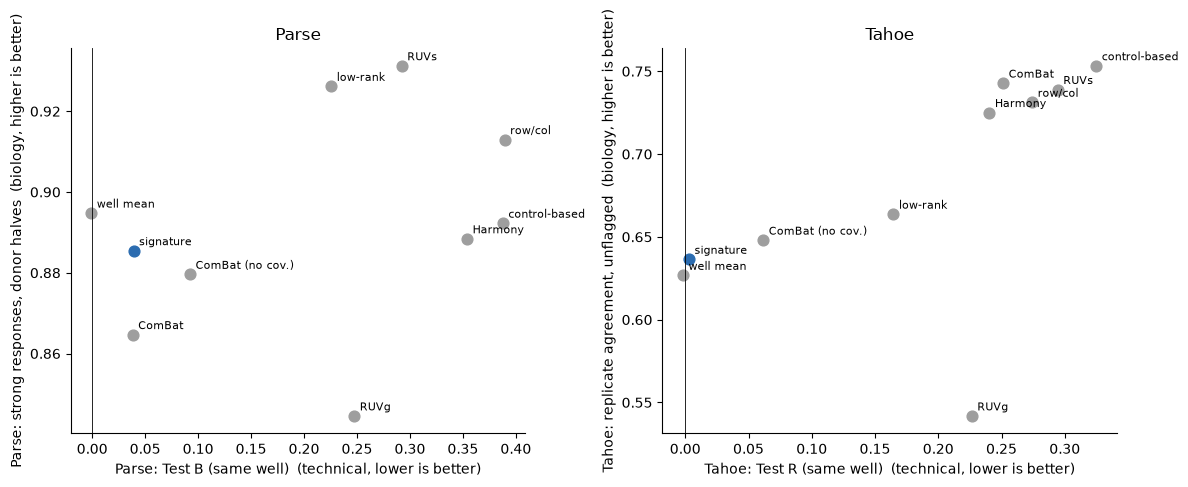

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_baselines/aim2_baselines.png
[whole notebook] 5192.0s | total 86.5 min


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
pairs_plot = [("Parse: Test B (same well)", "Parse: strong responses, donor halves", "Parse"),
              ("Tahoe: Test R (same well)", "Tahoe: replicate agreement, unflagged", "Tahoe")]
for a, (xk, yk, title) in zip(ax, pairs_plot):
    for m in METHODS:
        x, y = TAB4.loc[xk, m], TAB4.loc[yk, m]
        if np.isnan(x) or np.isnan(y):
            continue
        a.scatter(x, y, s=60, color="#2b6cb0" if m == "ours" else "#9e9e9e")
        a.annotate(m, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=8)
    a.axvline(0, color="k", lw=0.6)
    a.set_xlabel(xk + "  (technical, lower is better)")
    a.set_ylabel(yk + "  (biology, higher is better)")
    a.set_title(title)
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_baselines.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank"}

def rename_labels(fig, mapping=RENAME):
    for a in fig.axes:
        a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
        leg = a.get_legend()
        if leg:
            for t in leg.get_texts():
                t.set_text(mapping.get(t.get_text(), t.get_text()))
        for t in a.texts:                       # point labels, e.g. in aim2_baselines.png
            t.set_text(mapping.get(t.get_text(), t.get_text()))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png)
stamp(T_START, "whole notebook")

## 12. Diagnostic: why ComBat removes the well effect in Parse but not in Tahoe
Two explanations are tested together on Tahoe plate 6, in a 2 x 2 design: which lines build the well signature (all lines, or only the non-responders) and whether each line has its own slopes. ComBat is run next to them. Values are same well minus different wells (all responses share the DMSO reference, which raises both), unflagged wells only, partner excluded, by the number of responders in the well.

In [23]:
# Diagnostic: why does ComBat (well = batch) remove the well effect in Parse but not in Tahoe?
# Two explanations, tested together on Tahoe plate 6:
#   (H1) masks: a well mean over ALL lines also contains the drug response of the responders,
#        which is then subtracted from the non-responders too, so they share it again;
#   (H2) slopes: lines feel the well signature with different strengths, so one mean per well and gene is not enough.
# Four variants separate them (2 x 2: which lines build the signature x common or per-line slopes):
#   all lines, slope 1          ~ ComBat without empirical Bayes
#   non-responders, slope 1     masks only
#   all lines, per-line slopes  slopes only
#   non-responders, per-line    ours
# Read same well MINUS different wells: all responses share the DMSO reference, which raises both.
# Only unflagged wells (>= MIN_CTRL_TAHOE non-responders) are used, since flagged wells are not corrected by ours.
# Partner excluded: lines split into two halves, as in section 9. Run at the end of aim2_baselines.ipynb (same kernel).

def m_signature_slope1(Y, nr, min_ctrl=MIN_CTRL_TAHOE, **kw):
    """Leave-one-out signature of the non-responders (or of all lines), removed with slope 1."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    ok = nr & obs
    Y0z = np.nan_to_num(center_on(Y, ok))
    okf = ok.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    P[n_other < min_ctrl] = 0
    Y1 = Y0z - P
    Y1[~obs] = np.nan
    return Y1

t0 = time.time()
ALL = np.ones_like(T_NRA)
VARIANTS = {
    "ComBat":                     lambda Y, nr: m_combat(Y),
    "all lines, slope 1":         lambda Y, nr: m_signature_slope1(Y, ALL[:, :Y.shape[2]]),
    "non-responders, slope 1":    lambda Y, nr: m_signature_slope1(Y, nr),
    "all lines, per-line slopes": lambda Y, nr: m_signature(Y, ALL[:, :Y.shape[2]]),
    "ours (non-resp., per-line)": lambda Y, nr: m_signature(Y, nr),
    "control-based":              lambda Y, nr: Y,
}
n_resp = (~T_NRA).sum(1)                                   # responders per well on plate 6
unflagged = T_NRA.sum(1) >= MIN_CTRL_TAHOE
BINS = [(0, 2, "0-2"), (3, 9, "3-9"), (10, 999, ">=10")]
rows = []
for s in range(N_SPLITS):
    rng = np.random.default_rng(SEED + 200 + s)
    pl = rng.permutation(len(LINES))
    ht = [np.sort(pl[: len(LINES) // 2]), np.sort(pl[len(LINES) // 2:])]
    for name, f in VARIANTS.items():
        A = np.full_like(YT[pa], np.nan)
        for h in ht:
            A[:, :, h] = f(YT[pa][:, :, h], T_NRA[:, h])
        ra = contrast(A, T_CTRL)[0]
        for lo, hi, lab in BINS:
            wells = [k for k in np.where(~T_CTRL & unflagged)[0] if lo <= n_resp[k] <= hi]
            same, diff = [], []
            for i, k in enumerate(wells):
                a_ = [c for c in ht[0] if NR_BOTH[k, c] and not np.isnan(ra[k, c, 0])]
                b_ = [c for c in ht[1] if NR_BOTH[k, c] and not np.isnan(ra[k, c, 0])]
                for a, b in zip(a_[:10], b_[:10]):
                    same.append(spearmanr(ra[k, a], ra[k, b])[0])
                    v = wells[(i + 1) % len(wells)]               # a different well of the same bin
                    if v != k and not np.isnan(ra[v, b, 0]):
                        diff.append(spearmanr(ra[k, a], ra[v, b])[0])
            rows.append(dict(split=s, method=name, wells=lab, n_wells=len(wells), n_pairs=len(same),
                             same=np.median(same) if same else np.nan,
                             diff=np.median(diff) if diff else np.nan))
    print(f"  split {s + 1}/{N_SPLITS} {time.time() - t0:6.1f}s", flush=True)
DIAG = pd.DataFrame(rows)
DIAG["same_minus_diff"] = DIAG["same"] - DIAG["diff"]
DIAG.to_csv(os.path.join(OUT_DIR, "diag_combat_by_responders.csv"), index=False)
SUM = DIAG.groupby(["method", "wells"], sort=False)[["same", "diff", "same_minus_diff"]].median()
print("\nTwo non-responding lines, plate 6, partner excluded, unflagged wells (median over splits):")
print(SUM.same_minus_diff.unstack("wells").reindex(columns=[b[2] for b in BINS]).round(3).to_string())
print("\nSame well and different wells separately:")
print(SUM.round(3).to_string())
print("\nWells per bin:", DIAG[DIAG.split == 0].drop_duplicates("wells").set_index("wells").n_wells.to_dict())
stamp(t0, "ComBat diagnostic")


  split 1/3    4.0s
  split 2/3    7.8s
  split 3/3   11.7s

Two non-responding lines, plate 6, partner excluded, unflagged wells (median over splits):
wells                         0-2    3-9   >=10
method                                         
ComBat                      0.219  0.301  0.315
all lines, slope 1          0.005 -0.008  0.004
non-responders, slope 1     0.005 -0.003 -0.013
all lines, per-line slopes  0.005  0.016  0.004
ours (non-resp., per-line)  0.005  0.006  0.004
control-based               0.225  0.307  0.325

Same well and different wells separately:
                                   same   diff  same_minus_diff
method                     wells                               
ComBat                     0-2    0.560  0.332            0.219
                           3-9    0.571  0.275            0.301
                           >=10   0.508  0.198            0.315
all lines, slope 1         0-2    0.005  0.001            0.005
                           3-9   -0.0

## 13. Where should the responder masks matter?
In wells with many responders that are still corrected, "well mean" removes part of the responders' response from every cell of the well, because its signature uses all other cell types. "ours" uses only the non-responders. By number of responders per well:
* **leakage**: Pearson between a non-responder's corrected response and the responders' response direction in the same well, taken from independent data (Tahoe: the other plate; Parse: the other donor half; always corrected with "ours"). About 0 means nothing leaked; negative means the responders' response was subtracted. `leakage_null` uses the direction of a different well.
* **responders**: agreement between plates 6 and 14 (Tahoe) or donor halves (Parse), and size relative to uncorrected.

In [24]:
# Where should the responder masks matter? Wells with many responders that are still corrected (unflagged).
# "well mean" builds the signature from ALL other cell types, so part of the responders' response is removed from
# everyone in the well. "ours" builds it from non-responders only. Two measures, by number of responders per well:
#   leakage   : Pearson between a non-responder's corrected response and the responders' response direction in that
#               well (direction taken from independent data: the other plate in Tahoe, the other donor half in Parse,
#               always corrected with "ours"). Expected: about 0 if nothing leaks, negative if the responders' response
#               was subtracted. Null: the same with the direction of a different well.
#   responders: replicate agreement (Tahoe, plate 6 vs 14; Parse, two donor halves) and size relative to uncorrected.
t0 = time.time()
COMP = ["control-based", "well mean", "ours"]


def leak_rows(dataset, R, DIR, nr, wells, n_resp, bins, seed=SEED):
    """R [K,C,G] corrected responses to score; DIR [K,G] responder direction; nr [K,C] non-responders."""
    rng = np.random.default_rng(seed)
    out = []
    for lo, hi, lab in bins:
        ks = [k for k in wells if lo <= n_resp[k] <= hi and not np.isnan(DIR[k, 0])]
        same, null = [], []
        for k in ks:
            other = [v for v in ks if v != k]
            for c in np.where(nr[k])[0]:
                if np.isnan(R[k, c, 0]):
                    continue
                same.append(np.corrcoef(R[k, c], DIR[k])[0, 1])
                if other:
                    null.append(np.corrcoef(R[k, c], DIR[rng.choice(other)])[0, 1])
        out.append(dict(dataset=dataset, bin=lab, n_wells=len(ks), n_entries=len(same),
                        leakage=np.median(same) if same else np.nan,
                        leakage_null=np.median(null) if null else np.nan))
    return out

rows = []
# ---------------- Tahoe: plate 6 scored, direction from plate 14 corrected with "ours"
nrA = T_NRA
n_resp_T = (~nrA).sum(1)
wells_T = [k for k in np.where(~T_CTRL & T_UNFLAGGED)[0] if n_resp_T[k] >= 1]
rb_ours = contrast(TAHOE["ours"][1], T_CTRL)[0]
DIR_T = np.full((96, N_GENES), np.nan, np.float32)
for k in wells_T:
    DIR_T[k] = np.nanmean(rb_ours[k, ~nrA[k]], 0)
BINS_T = [(1, 2, "1-2"), (3, 9, "3-9"), (10, 999, ">=10")]
for m in COMP:
    ra, rb = contrast(TAHOE[m][0], T_CTRL)[0], contrast(TAHOE[m][1], T_CTRL)[0]
    r0a, r0b = contrast(TAHOE["control-based"][0], T_CTRL)[0], contrast(TAHOE["control-based"][1], T_CTRL)[0]
    for r in leak_rows("Tahoe", ra, DIR_T, nrA, wells_T, n_resp_T, BINS_T):
        lo, hi = [b[:2] for b in BINS_T if b[2] == r["bin"]][0]
        ks = [k for k in wells_T if lo <= n_resp_T[k] <= hi]
        agr, size = [], []
        for k in ks:
            for c in np.where(RESP_BOTH[k])[0]:
                if np.isnan(ra[k, c, 0] + rb[k, c, 0]):
                    continue
                agr.append(np.corrcoef(ra[k, c], rb[k, c])[0, 1])
                size.append(np.linalg.norm(ra[k, c]) / np.linalg.norm(r0a[k, c]))
        r.update(method=m, resp_agreement=np.median(agr) if agr else np.nan,
                 resp_size_vs_uncorrected=np.median(size) if size else np.nan, n_resp_entries=len(agr))
        rows.append(r)

# ---------------- Parse: donor half H2 scored, direction from half H1 corrected with "ours"
n_resp_P = (~P_NR).sum(1)
wells_P = [k for k in np.where(active)[0] if n_resp_P[k] >= 1 and (P_NR[k].sum() >= MIN_CTRL_PARSE)]
t1_ours = np.nanmean(contrast(PARSE["ours"], P_CTRL)[H1], 0)
DIR_P = np.full((96, N_GENES), np.nan, np.float32)
for k in wells_P:
    DIR_P[k] = np.nanmean(t1_ours[k, ~P_NR[k]], 0)
BINS_P = [(1, 1, "1"), (2, 3, "2-3"), (4, 6, ">=4")]
for m in COMP:
    d = contrast(PARSE[m], P_CTRL)
    t1, t2 = np.nanmean(d[H1], 0), np.nanmean(d[H2], 0)
    t2_0 = np.nanmean(contrast(PARSE["control-based"], P_CTRL)[H2], 0)
    for r in leak_rows("Parse", t2, DIR_P, P_NR, wells_P, n_resp_P, BINS_P):
        lo, hi = [b[:2] for b in BINS_P if b[2] == r["bin"]][0]
        ks = [k for k in wells_P if lo <= n_resp_P[k] <= hi]
        agr, size = [], []
        for k in ks:
            for c in np.where(~P_NR[k])[0]:
                if np.isnan(t1[k, c, 0] + t2[k, c, 0]):
                    continue
                agr.append(np.corrcoef(t1[k, c], t2[k, c])[0, 1])
                size.append(np.linalg.norm(t2[k, c]) / np.linalg.norm(t2_0[k, c]))
        r.update(method=m, resp_agreement=np.median(agr) if agr else np.nan,
                 resp_size_vs_uncorrected=np.median(size) if size else np.nan, n_resp_entries=len(agr))
        rows.append(r)

MASKTEST = pd.DataFrame(rows)[["dataset", "bin", "method", "n_wells", "n_entries", "leakage", "leakage_null",
                               "n_resp_entries", "resp_agreement", "resp_size_vs_uncorrected"]]
MASKTEST.to_csv(os.path.join(OUT_DIR, "mask_test_by_responders.csv"), index=False)
for ds in ["Tahoe", "Parse"]:
    print(f"\n{ds}: by number of responders per well (unflagged wells only)")
    print(MASKTEST[MASKTEST.dataset == ds].drop(columns="dataset").round(3).to_string(index=False))
stamp(t0, "mask test")



Tahoe: by number of responders per well (unflagged wells only)
 bin        method  n_wells  n_entries  leakage  leakage_null  n_resp_entries  resp_agreement  resp_size_vs_uncorrected
 1-2 control-based       11        512    0.049         0.027               0             NaN                       NaN
 3-9 control-based        7        301    0.074        -0.001               9           0.688                     1.000
>=10 control-based        8        196    0.124         0.060              16           0.776                     1.000
 1-2     well mean       11        512   -0.006         0.001               0             NaN                       NaN
 3-9     well mean        7        301   -0.019        -0.002               9           0.086                     0.476
>=10     well mean        8        196   -0.070        -0.016              16           0.677                     0.682
 1-2          ours       11        512   -0.002         0.002               0             NaN   

## 14. Is ComBat run correctly on Tahoe?
ComBat removed almost nothing in Tahoe (section 12), which is surprising with 48 lines per well. On plate 6: how much ComBat changes its input (after removing each line's own mean over wells), relative to the change made by the well mean; ComBat with and without the cell-line covariate; whether its change points the same way as the well-mean change; and the technical check of section 12.

In [25]:
# Section 14. Is ComBat run correctly on Tahoe? Plate 6 only.
# Checks: (1) how much ComBat changes its input, relative to how much the well mean changes it;
# (2) ComBat with and without the cell-line covariate; (3) whether ComBat's change points the same way as
# the well-mean change (correlation over genes, per entry); (4) the technical check of section 12
# (same well minus different wells, two lines that respond on neither plate, unflagged wells).
t0 = time.time()
Y6 = YT[pa]


def excess_same_well(R, wells, seed=SEED):
    """Same-well minus different-well median Spearman of two lines that respond on neither plate."""
    rng = np.random.default_rng(seed)
    same, diff = [], []
    for i, k in enumerate(wells):
        cs = [c for c in np.where(NR_BOTH[k])[0] if not np.isnan(R[k, c, 0])]
        rng.shuffle(cs)
        v = wells[(i + 1) % len(wells)]
        for a, b in zip(cs[0::2][:10], cs[1::2][:10]):
            same.append(spearmanr(R[k, a], R[k, b])[0])
            if not np.isnan(R[v, b, 0]):
                diff.append(spearmanr(R[k, a], R[v, b])[0])
    return np.median(same), np.median(diff), np.median(same) - np.median(diff)

VARS = {"uncorrected": Y6, "ComBat (covariate: line)": m_combat(Y6), "ComBat (no covariate)": m_combat_nocov(Y6),
        "well mean": m_wellmean(Y6)}
obs6 = ~np.isnan(Y6[0, :, :, 0])
# remove each line's own mean over wells, so that a pure re-centring per line does not count as a change
cen = lambda Z: Z[0] - np.nanmean(Z[0], 0, keepdims=True)
D_wm = cen(VARS["well mean"]) - cen(Y6)
wells_ok = [k for k in np.where(~T_CTRL & T_UNFLAGGED)[0]]
rows = []
for name, Z in VARS.items():
    D = cen(Z) - cen(Y6)
    size = np.nanmedian(np.linalg.norm(D[obs6], axis=-1))
    cor = [np.corrcoef(D[k, c], D_wm[k, c])[0, 1] for k in range(96) for c in range(len(LINES))
           if obs6[k, c] and np.linalg.norm(D[k, c]) > 0]
    s_, d_, e_ = excess_same_well(contrast(Z, T_CTRL)[0], wells_ok)
    rows.append(dict(method=name, median_change_size=size,
                     change_size_vs_well_mean=size / np.nanmedian(np.linalg.norm(D_wm[obs6], axis=-1)),
                     corr_with_well_mean_change=np.median(cor) if cor else np.nan,
                     same_well=s_, different_wells=d_, excess=e_))
COMBAT_CHECK = pd.DataFrame(rows).set_index("method")
COMBAT_CHECK.to_csv(os.path.join(OUT_DIR, "combat_check_plate6.csv"))
print(COMBAT_CHECK.round(3).to_string())
stamp(t0, "ComBat check")


                          median_change_size  change_size_vs_well_mean  corr_with_well_mean_change  same_well  different_wells  excess
method                                                                                                                                
uncorrected                            0.000                     0.000                         NaN      0.574            0.334   0.240
ComBat (covariate: line)               1.353                     0.209                       0.804      0.517            0.297   0.220
ComBat (no covariate)                  5.230                     0.808                       0.994      0.049            0.024   0.026
well mean                              6.469                     1.000                       1.000     -0.022           -0.014  -0.009
[ComBat check] 3.5s | total 20.6 min


In [26]:
# Section 17 of aim2_baselines.ipynb (after section 14): why does ComBat with the cell-line covariate leave the
# well effect in Tahoe-100M? Plate 6 only. Uses Y6, m_combat, m_combat_nocov, m_wellmean, long_obs, back_to_tensor,
# excess_same_well, cen, contrast, T_CTRL, T_UNFLAGGED from sections 2 and 14.
# Six corrections, all with the well as batch, scored like section 14 (size of the change relative to the well mean,
# its correlation with the well-mean change, and the excess same-well correlation of two non-responding lines):
#   scanpy, line covariate / scanpy, no covariate   (as before)
#   own ComBat, line covariate                       (Johnson et al. 2007: standardize, batch mean and variance, EB)
#   own ComBat, line covariate, no EB                (batch mean and variance as estimated, no shrinkage)
#   own ComBat, line covariate, mean only            (no EB, no variance step)
#   fixed effects                                    (least squares y = well + line, well effect removed)
# Reading, fixed before running: if our own ComBat with the covariate removes the effect but scanpy's does not, the
# cause is the scanpy implementation; if only the no-EB and mean-only versions remove it, the cause is the empirical
# Bayes shrinkage; if none of the covariate versions remove it, the cause is the model with the covariate itself.
t0 = time.time()


def own_combat(Y, covariate=True, eb=True, mean_only=False, n_iter=100, tol=1e-4):
    d, k, c, X = long_obs(Y)                                   # X: entries x genes
    X = X.astype(np.float64)
    batch = pd.Categorical([f"{a}_{b}" for a, b in zip(d, k)])
    nb = len(batch.categories)
    Bm = np.eye(nb)[batch.codes]                               # entries x batches
    Dm = Bm
    if covariate:
        lines = pd.Categorical(c)
        Cm = np.eye(len(lines.categories))[lines.codes][:, 1:]
        Dm = np.hstack([Bm, Cm])
    beta, *_ = np.linalg.lstsq(Dm, X, rcond=None)
    n_per = Bm.sum(0)
    grand = (n_per / n_per.sum()) @ beta[:nb]                  # genes
    stand = grand[None] + (Dm[:, nb:] @ beta[nb:] if covariate else 0)
    var_pooled = ((X - Dm @ beta) ** 2).mean(0)
    sd = np.sqrt(np.maximum(var_pooled, 1e-12))
    S = (X - stand) / sd
    gam = np.vstack([S[batch.codes == b].mean(0) for b in range(nb)])                 # batches x genes
    dlt = np.vstack([S[batch.codes == b].var(0, ddof=1) for b in range(nb)])
    if mean_only:
        dlt = np.ones_like(dlt)
    if eb:
        gbar, t2 = gam.mean(1, keepdims=True), gam.var(1, ddof=1, keepdims=True)
        m, v = dlt.mean(1, keepdims=True), dlt.var(1, ddof=1, keepdims=True)
        a_pr, b_pr = (2 * v + m ** 2) / v, (m * v + m ** 3) / v
        g_new, d_new = gam.copy(), dlt.copy()
        for b in range(nb):
            Sb = S[batch.codes == b]; n = len(Sb)
            g_old, d_old = gam[b], dlt[b]
            for _ in range(n_iter):
                g_n = (t2[b] * n * gam[b] + d_old * gbar[b]) / (t2[b] * n + d_old)
                ssq = ((Sb - g_n) ** 2).sum(0)
                d_n = d_old if mean_only else (b_pr[b] + 0.5 * ssq) / (n / 2 + a_pr[b] - 1)
                done = max(np.abs(g_n - g_old).max() / (np.abs(g_old).max() + 1e-12),
                           np.abs(d_n - d_old).max() / (np.abs(d_old).max() + 1e-12)) < tol
                g_old, d_old = g_n, d_n
                if done:
                    break
            g_new[b], d_new[b] = g_old, d_old
        gam, dlt = g_new, d_new
    adj = (S - gam[batch.codes]) / np.sqrt(dlt[batch.codes]) * sd + stand
    return back_to_tensor(Y, d, k, c, adj.astype(Y.dtype))


def fixed_effects(Y):
    """Least squares y = well + line per gene; the well effect is removed, the line effect kept."""
    d, k, c, X = long_obs(Y)
    w = pd.Categorical([f"{a}_{b}" for a, b in zip(d, k)]); l = pd.Categorical(c)
    nb = len(w.categories)
    Dm = np.hstack([np.eye(nb)[w.codes], np.eye(len(l.categories))[l.codes][:, 1:]])
    beta, *_ = np.linalg.lstsq(Dm, X.astype(np.float64), rcond=None)
    well_eff = beta[:nb] - beta[:nb].mean(0, keepdims=True)
    return back_to_tensor(Y, d, k, c, (X - well_eff[w.codes]).astype(Y.dtype))


VARS2 = {"uncorrected": Y6,
         "scanpy ComBat, line covariate": m_combat(Y6),
         "scanpy ComBat, no covariate": m_combat_nocov(Y6),
         "own ComBat, line covariate": own_combat(Y6, True, True),
         "own ComBat, line covariate, no EB": own_combat(Y6, True, False),
         "own ComBat, line covariate, mean only": own_combat(Y6, True, False, True),
         "own ComBat, no covariate": own_combat(Y6, False, True),
         "fixed effects (well + line)": fixed_effects(Y6),
         "well mean": m_wellmean(Y6)}
obs6 = ~np.isnan(Y6[0, :, :, 0])
D_wm = cen(VARS2["well mean"]) - cen(Y6)
wells_ok = [k for k in np.where(~T_CTRL & T_UNFLAGGED)[0]]
rows = []
for name, Z in VARS2.items():
    Dz = cen(Z) - cen(Y6)
    size = np.nanmedian(np.linalg.norm(Dz[obs6], axis=-1))
    cor = [np.corrcoef(Dz[k, c_], D_wm[k, c_])[0, 1] for k in range(96) for c_ in range(Y6.shape[2])
           if obs6[k, c_] and np.linalg.norm(Dz[k, c_]) > 0]
    s_, d_, e_ = excess_same_well(contrast(Z, T_CTRL)[0], wells_ok)
    rows.append(dict(method=name, change_vs_well_mean=size / np.nanmedian(np.linalg.norm(D_wm[obs6], axis=-1)),
                     corr_with_well_mean_change=np.median(cor) if cor else np.nan, same_well=s_, different_wells=d_, excess=e_))
    print(f"  {name:40s} done {time.time() - t0:.0f}s", flush=True)
CB = pd.DataFrame(rows).set_index("method")
CB.to_csv(os.path.join(OUT_DIR, "combat_diagnosis_plate6.csv"))
print(CB.round(3).to_string())
ex = CB.excess
gone = lambda m: ex[m] < 0.05
print("\nReading (excess below 0.05 counts as removed):")
print(f"  own ComBat with covariate removes it: {gone('own ComBat, line covariate')} | scanpy with covariate: {gone('scanpy ComBat, line covariate')}")
print(f"  no EB: {gone('own ComBat, line covariate, no EB')} | mean only: {gone('own ComBat, line covariate, mean only')} | "
      f"fixed effects: {gone('fixed effects (well + line)')}")
stamp(t0, "ComBat diagnosis")

# ---- Is scanpy's design matrix singular? scanpy.pp.combat builds the batch columns and, for a categorical covariate,
# a full set of dummy columns (patsy "~ 0 + covariate"), so batch and covariate columns both sum to one and the design
# loses one rank; it then inverts X'X with numpy.linalg.inv, not a pseudo-inverse.
from scanpy.preprocessing._combat import _design_matrix
d_, k_, c_, X_ = long_obs(Y6)
model = pd.DataFrame({"batch": pd.Categorical([f"{a}_{b}" for a, b in zip(d_, k_)]).astype(str),
                      "line": pd.Categorical(c_).astype(str)})
lev = tuple(model.groupby("batch", observed=True).groups.keys())
Dsc = _design_matrix(model, "batch", lev).to_numpy(dtype=float)
rk = np.linalg.matrix_rank(Dsc)
print(f"\nscanpy design with the line covariate: {Dsc.shape[1]} columns, rank {rk} "
      f"({'singular' if rk < Dsc.shape[1] else 'full rank'}); condition number of X'X {np.linalg.cond(Dsc.T @ Dsc):.2e}")

  uncorrected                              done 2s
  scanpy ComBat, line covariate            done 3s
  scanpy ComBat, no covariate              done 4s
  own ComBat, line covariate               done 4s
  own ComBat, line covariate, no EB        done 5s
  own ComBat, line covariate, mean only    done 6s
  own ComBat, no covariate                 done 6s
  fixed effects (well + line)              done 7s
  well mean                                done 8s
                                       change_vs_well_mean  corr_with_well_mean_change  same_well  different_wells  excess
method                                                                                                                    
uncorrected                                          0.000                         NaN      0.574            0.334   0.240
scanpy ComBat, line covariate                        0.209                       0.804      0.517            0.297   0.220
scanpy ComBat, no covariate                      

## 15. Which part of the estimator does what?
One ingredient at a time: responder masks, per-gene slopes, two-part signature (Parse only) and the flag rule. Every variant gets the checks of Table 4 and the leakage test of section 13.

**Interpretation fixed before running:**
* **Q1, flag rule.** If "well mean + flag" is within 0.02 of ours on the agreement of all 163 strong Tahoe responses, the advantage of ours there (0.85 vs 0.78) comes from the flag rule, which can be put on any estimator, not from the estimator.
* **Q2, masks.** Masks are needed in Parse if, in wells with 2-3 responding cell types, every unmasked variant leaks (leakage below -0.10) and every masked variant does not (within +-0.05). Otherwise the evidence for masks is not sufficient. In Tahoe, masks are not needed if masked and unmasked variants differ by less than 0.05 in leakage in every group.
* **Q3, two-part.** If "all lines, two-part" is within 0.02 of ours on all three Parse biology checks, the difference between the well mean and ours in Parse comes from the two-part signature, not from the masks.

In [48]:
# Section 15. Which part of the estimator does what? One ingredient at a time.
# Ingredients: responder masks (controls = non-responders only), per-gene slopes, two-part signature (Parse only,
# where donors share the layout), and the flag rule (an entry with fewer than MIN_CTRL other non-responders is
# not corrected). Every variant is scored with the checks of Table 4 and the leakage test of section 13.
# Interpretation fixed before running (see the markdown above this cell).
t0 = time.time()


def m_wellmean_flag(Y, nr, min_ctrl, **kw):
    """Well mean from all other cell types, slope one, but entries flagged as in 'ours' are left uncorrected."""
    D, K, Cn, G = Y.shape
    obs = ~np.isnan(Y[..., 0])
    nr = np.broadcast_to(nr, (D, K, Cn)) if nr.ndim == 2 else nr
    Y0z = np.nan_to_num(center_on(Y, obs))
    okf = obs.astype(np.float32)
    S = np.einsum("dkc,dkcg->dkg", okf, Y0z)
    n_other = okf.sum(-1)[..., None] - okf
    P = (S[:, :, None, :] - okf[..., None] * Y0z) / np.maximum(n_other, 1)[..., None]
    nrf = (nr & obs).astype(np.float32)
    n_other_nr = nrf.sum(-1)[..., None] - nrf
    P[(n_other < 1) | (n_other_nr < min_ctrl)] = 0
    Y1 = Y0z - P
    Y1[~obs] = np.nan
    return Y1


def ALLNR(nr):
    return np.ones_like(nr)

LADDER = {   # name: (Parse function, Tahoe function); None = not applicable
    "1 well mean":                       (lambda Y, nr, m: m_wellmean(Y),                       lambda Y, nr, m: m_wellmean(Y)),
    "2 well mean + flag":                (lambda Y, nr, m: m_wellmean_flag(Y, nr, m),           lambda Y, nr, m: m_wellmean_flag(Y, nr, m)),
    "3 all lines, per-gene slopes":      (lambda Y, nr, m: m_signature(Y, ALLNR(nr), 1),        lambda Y, nr, m: m_signature(Y, ALLNR(nr), 1)),
    "4 all lines, two-part":             (lambda Y, nr, m: m_signature2(Y, ALLNR(nr), 1),       None),
    "5 masks, slope 1 + flag":           (lambda Y, nr, m: m_signature_slope1(Y, nr, m),        lambda Y, nr, m: m_signature_slope1(Y, nr, m)),
    "6 masks, per-gene slopes + flag":   (lambda Y, nr, m: m_signature(Y, nr, m),               lambda Y, nr, m: m_signature(Y, nr, m)),
    "7 masks, two-part + flag (ours P)": (lambda Y, nr, m: m_signature2(Y, nr, m),              None),
}


def halves_fit(f, Y, nr, minc, halves):
    Y1 = np.full_like(Y, np.nan)
    for h in halves:
        Y1[:, :, h] = f(Y[:, :, h], nr[:, h], minc)
    return Y1


rows = []
for name, (fP, fT) in LADDER.items():
    t1 = time.time()
    r = {"variant": name}
    # ---------------- Parse
    YPc = fP(YP, P_NR, MIN_CTRL_PARSE)
    diff = contrast(YPc, P_CTRL)
    tau = np.nanmean(diff, 0)
    size = np.linalg.norm(tau, axis=-1)
    t1h, t2h = np.nanmean(diff[H1], 0), np.nanmean(diff[H2], 0)
    s_rec = size[REC[:, 0], REC[:, 1]]
    r["P inert size"] = np.nanmedian(size[P_INERT]) / REF
    r["P strong, donor halves"] = np.nanmedian([np.corrcoef(t1h[k, c], t2h[k, c])[0, 1] for k, c in TOP])
    r["P strong size"] = np.median([size[k, c] for k, c in TOP]) / REF
    r["P receptor AUROC"] = auroc(s_rec[REC[:, 2] == 1], s_rec[REC[:, 2] == 0])
    B = []
    for s in range(N_SPLITS):
        pc = np.random.default_rng(SEED + 100 + s).permutation(len(CELL_TYPES)); hp = [np.sort(pc[:3]), np.sort(pc[3:])]
        R = contrast(halves_fit(fP, YP, P_NR, MIN_CTRL_PARSE, hp), P_CTRL)[:, P_INERT].reshape(-1, len(CELL_TYPES), N_GENES)
        B += pairs_same_diff(R, np.arange(len(R)), hp[0], hp[1], seed=SEED + s)[0]
    r["P Test B, partner excl."] = np.median(B)
    for lr in leak_rows("Parse", t2h, DIR_P, P_NR, wells_P, n_resp_P, BINS_P):
        r[f"P leakage {lr['bin']}"] = lr["leakage"]
    # ---------------- Tahoe
    if fT is not None:
        A, Bp = fT(YT[pa], T_NRA, MIN_CTRL_TAHOE), fT(YT[pb_], T_NRB, MIN_CTRL_TAHOE)
        ra, rb = contrast(A, T_CTRL)[0], contrast(Bp, T_CTRL)[0]
        ks, cs = np.where(RESP_BOTH)
        agr = np.array([np.corrcoef(ra[k, c], rb[k, c])[0, 1] if not np.isnan(ra[k, c, 0] + rb[k, c, 0]) else np.nan
                        for k, c in zip(ks, cs)])
        r["T agreement, 163 strong"] = np.nanmedian(agr)
        r["T agreement, unflagged"] = np.nanmedian(agr[T_UNFLAGGED[ks]])
        r["T agreement, flagged wells"] = np.nanmedian(agr[~T_UNFLAGGED[ks]])
        r["T genotype AUROC"] = np.nanmedian([auroc(np.linalg.norm(x[k], axis=-1)[CARRIER], np.linalg.norm(x[k], axis=-1)[~CARRIER])
                                              for x in (ra, rb) for k in T_WELLS])
        Rr, Tn = [], []
        for s in range(N_SPLITS):
            pl = np.random.default_rng(SEED + 100 + s).permutation(len(LINES)); ht = [np.sort(pl[: len(LINES) // 2]), np.sort(pl[len(LINES) // 2:])]
            A2 = contrast(halves_fit(fT, YT[pa], T_NRA, MIN_CTRL_TAHOE, ht), T_CTRL)[0]
            B2 = contrast(halves_fit(fT, YT[pb_], T_NRB, MIN_CTRL_TAHOE, ht), T_CTRL)[0]
            d = A2 - B2
            d = d - np.nanmean(d[~T_CTRL], 0, keepdims=True)
            Rr += pairs_same_diff(d, ok_wells, ht[0], ht[1], seed=SEED + s)[0]
            Tn += pairs_same_diff(A2, ok_wells, ht[0], ht[1], ok=NR_BOTH, seed=SEED + s)[0]
        r["T Test R, partner excl."] = np.median(Rr)
        r["T non-resp. lines, partner excl."] = np.median(Tn)
        for lr in leak_rows("Tahoe", ra, DIR_T, T_NRA, wells_T, n_resp_T, BINS_T):
            r[f"T leakage {lr['bin']}"] = lr["leakage"]
    rows.append(r)
    print(f"  {name:36s} {time.time() - t1:6.1f}s", flush=True)
ABL = pd.DataFrame(rows).set_index("variant").T
ABL.to_csv(os.path.join(OUT_DIR, "ablation_ingredients.csv"))
print(ABL.round(3).to_string())

# ---- the three questions, answered by the rules fixed in advance
o_T = "6 masks, per-gene slopes + flag"
q1 = abs(ABL.loc["T agreement, 163 strong", "2 well mean + flag"] - ABL.loc["T agreement, 163 strong", o_T]) <= 0.02
leak_un = ABL.loc["P leakage 2-3", ["1 well mean", "3 all lines, per-gene slopes", "4 all lines, two-part"]]
leak_m = ABL.loc["P leakage 2-3", ["5 masks, slope 1 + flag", "6 masks, per-gene slopes + flag", "7 masks, two-part + flag (ours P)"]]
q2 = bool((leak_un < -0.10).all() and (leak_m.abs() <= 0.05).all())
bio = ["P strong, donor halves", "P strong size", "P receptor AUROC"]
q3 = bool((ABL.loc[bio, "4 all lines, two-part"] - ABL.loc[bio, "7 masks, two-part + flag (ours P)"]).abs().max() <= 0.02)
print(f"\nQ1 Tahoe 0.85 vs 0.78 comes from the flag rule, not the estimator: {q1}")
print(f"Q2 masks needed in Parse wells with 2-3 responders (unmasked leak < -0.10, masked within +-0.05): {q2}")
print(f"Q3 on Parse biology, two-part without masks matches ours (all within 0.02): {q3}")
stamp(t0, "ingredients")


  1 well mean                            11.7s
  2 well mean + flag                     11.7s
  3 all lines, per-gene slopes           11.9s
  4 all lines, two-part                   4.3s
  5 masks, slope 1 + flag                11.7s
  6 masks, per-gene slopes + flag        11.9s
  7 masks, two-part + flag (ours P)       4.3s
variant                           1 well mean  2 well mean + flag  3 all lines, per-gene slopes  4 all lines, two-part  5 masks, slope 1 + flag  6 masks, per-gene slopes + flag  7 masks, two-part + flag (ours P)
P inert size                            0.127               0.127                         0.145                  0.146                    0.127                            0.146                              0.145
P strong, donor halves                  0.895               0.890                         0.913                  0.902                    0.887                            0.896                              0.885
P strong size                      

## 16. Can the leakage of the well mean be predicted before it is run?
Section 13 measured how much of the responders' response the well mean removes from the other cells of the well. Here we predict it from three quantities that do not use the well-mean output (the leakage proposition of Paper 2, label prop:leak):
* **share** `a = m/(n-1)`: responders among the other cell types of the well;
* **size of the mean response** `|rbar|`, which depends on how **aligned** the responders' responses are: between `1/sqrt(m)` of one response (unrelated responses) and one response (the same response);
* **noise** `|eta_c|` of the non-responder (its response corrected with "ours").

Predicted leakage: `rho = - reliability * z / sqrt(1 + z^2)`, with `z = a * |rbar| / |eta_c|` and `reliability` = how well the independent direction matches the true one. Squared norms are estimated by cross-products between independent halves (plates 6 and 14; donor halves), so noise does not inflate them.

**Criteria fixed before running:**
* **C1.** In every bin of section 13 with at least two wells (both data sets), the median predicted leakage is within 0.05 of the observed one.
* **C2.** Over all wells of both data sets, Spearman between predicted and observed well medians is at least 0.5.

If both hold, the rule "masks are needed in a well when the predicted leakage is below -0.10" can be applied to a screen before the well mean is run. The design table at the end gives the predicted leakage for screens not run yet.


              n_wells  share  alignment  alignment_if_unaligned    snr  predicted  observed  abs_error
dataset bin                                                                                           
Tahoe   3-9         7  0.085      0.538                   0.500  0.792     -0.011    -0.020      0.009
        >=10        8  0.468      0.272                   0.213  0.821     -0.089    -0.098      0.010
        1-2        11  0.021      0.640                   1.000  0.733     -0.004    -0.010      0.005
Parse   1          21  0.200        NaN                   1.000    NaN     -0.074    -0.010      0.064
        2-3         4  0.400      0.683                   0.707  1.750     -0.373    -0.435      0.062
        >=4         1  0.800      0.599                   0.500  0.895     -0.331    -0.478      0.147

C1 every bin with >= 2 wells: |predicted - observed| <= 0.05 : False
C2 wells pooled over both data sets: Spearman(predicted, observed) = 0.65 (>= 0.5): True
   within data se

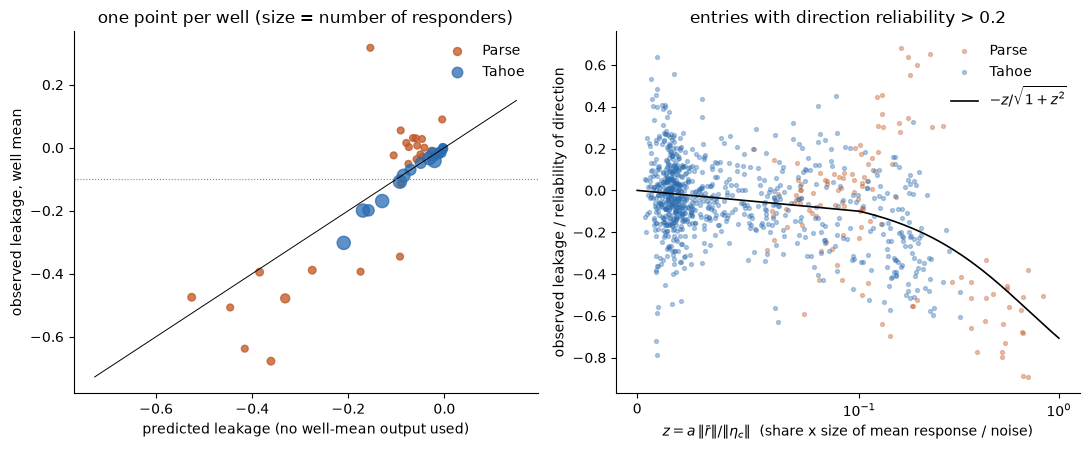

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_baselines/leakage_theory.png

Predicted well-mean leakage by design (columns: responses, signal-to-noise of one response):
responses             same response       unrelated      
snr                               1     3         1     3
cell_types responders                                    
6          1                  -0.20 -0.51     -0.20 -0.51
           2                  -0.37 -0.77     -0.27 -0.65
           3                  -0.51 -0.87     -0.33 -0.72
12         3                  -0.26 -0.63     -0.16 -0.43
48         3                  -0.06 -0.19     -0.04 -0.11
           10                 -0.21 -0.54     -0.07 -0.20
           20                 -0.39 -0.79     -0.09 -0.27
96         10                 -0.10 -0.30     -0.03 -0.10
[leakage theory] 5.6s | total 60.7 min


In [49]:
# Section 16. Predicting the leakage of the well mean before running it (the leakage proposition of Paper 2, label prop:leak).
# For a non-responder c in a well with n observed cell types, m of them responders with responses r_j, the well mean
# subtracts (1/(n-1)) * sum_j r_j from c. With a = m/(n-1) (share of responders), rbar = mean responder response,
# eta_c = c's own noise, d = responder direction from independent data (all vectors centred over genes):
#     rho_pred = - a <rbar, d> / ( |d| * sqrt(|eta_c|^2 + a^2 |rbar|^2) )
# |rbar|^2 and <rbar, d> are estimated by the cross-product <rbar_scored, d>, which has no noise bias because the two
# halves are independent; |eta_c| is c's response corrected with "ours" (no leak, since ours uses non-responders only).
# Nothing here uses the well-mean output: the well mean is only used for the observed leakage it is compared with.
t0 = time.time()
cen_g = lambda v: v - v.mean(-1, keepdims=True)     # centre over genes, so inner products give Pearson correlations


def leak_theory(dataset, R_wm, R_ours, R_ours_ind, DIR, nr, a_share, wells, n_resp, bins):
    """R_* [K,C,G]: scored data corrected with the well mean / ours; R_ours_ind: independent data, ours.
    a_share [K]: share of responders among the other cell types of the well."""
    ent, wl = [], []
    for k in wells:
        if np.isnan(DIR[k, 0]):
            continue
        resp = [j for j in np.where(~nr[k])[0] if not np.isnan(R_ours[k, j, 0])]
        resp_i = [j for j in resp if not np.isnan(R_ours_ind[k, j, 0])]
        if not resp:
            continue
        d = cen_g(DIR[k].astype(np.float64))
        rbar = cen_g(np.mean(R_ours[k, resp], 0).astype(np.float64))
        X = float(rbar @ d)                                   # estimates <rbar_true, d> and |rbar_true|^2
        a = a_share[k]
        # alignment of the responders' responses with each other, from cross-products between independent halves
        if len(resp_i) >= 2:
            RA = cen_g(R_ours[k, resp_i].astype(np.float64)); RB = cen_g(R_ours_ind[k, resp_i].astype(np.float64))
            q2 = np.mean(np.sum(RA * RB, 1))                  # mean squared norm of a single response
            rb2 = float(RA.mean(0) @ RB.mean(0))               # squared norm of the mean response
            align = np.sqrt(max(rb2, 0) / q2) if q2 > 0 else np.nan
        else:
            q2, align = np.nan, np.nan
        obs_k, pred_k = [], []
        for c in np.where(nr[k])[0]:
            if np.isnan(R_wm[k, c, 0]) or np.isnan(R_ours[k, c, 0]):
                continue
            eta2 = float(np.sum(cen_g(R_ours[k, c].astype(np.float64)) ** 2))
            pred = -a * X / (np.linalg.norm(d) * np.sqrt(eta2 + a ** 2 * max(X, 0)))
            obs = np.corrcoef(R_wm[k, c], DIR[k])[0, 1]
            ent.append(dict(dataset=dataset, well=WELLS[k], m=n_resp[k], a=a, observed=obs, predicted=pred,
                            z=a * np.sqrt(max(X, 0) / eta2), reliability=np.sqrt(max(X, 0)) / np.linalg.norm(d)))
            obs_k.append(obs); pred_k.append(pred)
        if obs_k:
            bin_ = [lab for lo, hi, lab in bins if lo <= n_resp[k] <= hi][0]
            wl.append(dict(dataset=dataset, well=WELLS[k], bin=bin_, m=n_resp[k], a=a,
                           alignment=align, alignment_if_unaligned=1 / np.sqrt(len(resp)),
                           snr=np.sqrt(q2 / np.median([np.sum(cen_g(R_ours[k, c].astype(np.float64)) ** 2)
                                                         for c in np.where(nr[k])[0] if not np.isnan(R_ours[k, c, 0])]))
                               if q2 == q2 and q2 > 0 else np.nan,
                           observed=np.median(obs_k), predicted=np.median(pred_k)))
    return pd.DataFrame(ent), pd.DataFrame(wl)

# ---------------- Tahoe: plate 6 scored, plate 14 independent
Y6obs = ~np.isnan(YT[pa][0, :, :, 0])
nT = Y6obs.sum(1)
a_T = ((~T_NRA) & Y6obs).sum(1) / np.maximum(nT - 1, 1)
ra_wm = contrast(TAHOE["well mean"][0], T_CTRL)[0]
ra_ours = contrast(TAHOE["ours"][0], T_CTRL)[0]
eT, wT = leak_theory("Tahoe", ra_wm, ra_ours, rb_ours, DIR_T, T_NRA, a_T, wells_T, n_resp_T, BINS_T)

# ---------------- Parse: donor half H2 scored, half H1 independent; the share is averaged over the H2 donors
obsP = ~np.isnan(YP[..., 0])                                  # [D, K, C]
a_P = np.nanmean(((~P_NR[None]) & obsP).sum(-1)[H2] / np.maximum(obsP.sum(-1)[H2] - 1, 1), 0)
t2_wm = np.nanmean(contrast(PARSE["well mean"], P_CTRL)[H2], 0)
t2_ours = np.nanmean(contrast(PARSE["ours"], P_CTRL)[H2], 0)
eP, wP = leak_theory("Parse", t2_wm, t2_ours, t1_ours, DIR_P, P_NR, a_P, wells_P, n_resp_P, BINS_P)

ENT = pd.concat([eT, eP], ignore_index=True)
WL = pd.concat([wT, wP], ignore_index=True)
ENT.to_csv(os.path.join(OUT_DIR, "leakage_theory_entries.csv"), index=False)
WL.to_csv(os.path.join(OUT_DIR, "leakage_theory_wells.csv"), index=False)

BIN_TAB = (WL.groupby(["dataset", "bin"], sort=False)
             .agg(n_wells=("well", "size"), share=("a", "median"), alignment=("alignment", "median"),
                  alignment_if_unaligned=("alignment_if_unaligned", "median"), snr=("snr", "median"),
                  predicted=("predicted", "median"), observed=("observed", "median")))
BIN_TAB["abs_error"] = (BIN_TAB.predicted - BIN_TAB.observed).abs()
BIN_TAB.to_csv(os.path.join(OUT_DIR, "leakage_theory_bins.csv"))
print(BIN_TAB.round(3).to_string())

# ---------------- criteria fixed before running (markdown above)
crit_bins = BIN_TAB[BIN_TAB.n_wells >= 2]
c1 = bool((crit_bins.abs_error <= 0.05).all())
rho_w = spearmanr(WL.predicted, WL.observed)[0]
c2 = bool(rho_w >= 0.5)
slope = np.polyfit(WL.predicted, WL.observed, 1)[0]
print(f"\nC1 every bin with >= 2 wells: |predicted - observed| <= 0.05 : {c1}")
print(f"C2 wells pooled over both data sets: Spearman(predicted, observed) = {rho_w:.2f} (>= 0.5): {c2}")
print(f"   within data set: Tahoe {spearmanr(wT.predicted, wT.observed)[0]:.2f} ({len(wT)} wells), "
      f"Parse {spearmanr(wP.predicted, wP.observed)[0]:.2f} ({len(wP)} wells); least-squares slope {slope:.2f}")

# ---------------- the practical rule: masks are needed in a well if the predicted leakage is beyond -0.10
need_pred, need_obs = WL.predicted < -0.10, WL.observed < -0.10
print(f"\nRule 'masks needed if predicted leakage < -0.10': {int(need_pred.sum())} wells flagged, "
      f"{int((need_pred & need_obs).sum())} of {int(need_obs.sum())} wells with observed leakage < -0.10 caught, "
      f"{int((need_pred & ~need_obs).sum())} false alarms")

# ---------------- figure: (a) observed against predicted per well; (b) collapse onto one curve
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
col = {"Tahoe": "#2b6cb0", "Parse": "#c05621"}
for ds, g in WL.groupby("dataset"):
    ax[0].scatter(g.predicted, g.observed, s=18 + 6 * g.m.clip(upper=12), color=col[ds], alpha=0.75, label=ds)
lim = [min(WL.predicted.min(), WL.observed.min()) - 0.05, 0.15]
ax[0].plot(lim, lim, color="k", lw=0.7); ax[0].axhline(-0.10, color="grey", ls=":", lw=0.8)
ax[0].set_xlabel("predicted leakage (no well-mean output used)"); ax[0].set_ylabel("observed leakage, well mean")
ax[0].set_title("one point per well (size = number of responders)"); ax[0].legend(frameon=False)
zz = np.linspace(0, max(ENT.z.max(), 1), 200)
for ds, g in ENT.groupby("dataset"):
    ok = g.reliability > 0.2
    ax[1].scatter(g.z[ok], g.observed[ok] / g.reliability[ok], s=8, color=col[ds], alpha=0.35, label=ds)
ax[1].plot(zz, -zz / np.sqrt(1 + zz ** 2), color="k", lw=1.2, label=r"$-z/\sqrt{1+z^2}$")
ax[1].set_xscale("symlog", linthresh=0.1)
ax[1].set_xlabel(r"$z = a\,\|\bar r\| / \|\eta_c\|$  (share x size of mean response / noise)")
ax[1].set_ylabel("observed leakage / reliability of direction")
ax[1].set_title("entries with direction reliability > 0.2"); ax[1].legend(frameon=False)
for a_ in ax:
    a_.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "leakage_theory.png"))
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf")); plt.show()
print("Saved:", png)

# ---------------- design table: predicted leakage for a screen that has not been run yet
# |rho| ~ z / sqrt(1 + z^2), z = a * alignment * snr, alignment between 1/sqrt(m) (unrelated responses) and 1 (same).
DESIGN = []
for n_ct, m_ in [(6, 1), (6, 2), (6, 3), (12, 3), (48, 3), (48, 10), (48, 20), (96, 10)]:
    a_ = m_ / (n_ct - 1)
    for lab, al in [("unrelated", 1 / np.sqrt(m_)), ("same response", 1.0)]:
        for snr in [1, 3]:
            z_ = a_ * al * snr
            DESIGN.append(dict(cell_types=n_ct, responders=m_, responses=lab, snr=snr, predicted_leakage=-z_ / np.sqrt(1 + z_ ** 2)))
DESIGN = pd.DataFrame(DESIGN).pivot_table(index=["cell_types", "responders"], columns=["responses", "snr"],
                                          values="predicted_leakage")
DESIGN.to_csv(os.path.join(OUT_DIR, "leakage_design_table.csv"))
print("\nPredicted well-mean leakage by design (columns: responses, signal-to-noise of one response):")
print(DESIGN.round(2).to_string())
stamp(t0, "leakage theory")
